06 10 月实盘窗口评估
修改下面的 `LIVE_START` / `LIVE_END` 即可。**参数只用 LIVE_START 之前的数据选出并冻结**，然后从 LIVE_START 开盘建仓模拟。

10/24 之后重新下载 CSV 覆盖 `etf_daily.csv`，再从头运行即可。

In [1]:
%run 00_engine.ipynb

数据区间: 2011-10-03 ~ 2026-10-07 | 信号分布: {'TQQQ': 2904, 'TECL': 249, 'TECS': 203, 'BSV': 150, 'UVXY': 133, 'SPXL': 17}


In [ ]:
LIVE_START='2026-10-01'
LIVE_END='2026-10-24'

用 2026-09-30 及以前的数据选参（冻结）: 固定 止损=0.12 止盈=0.15 | 数据最后一天: 2026-10-07


,方案,区间,交易日,累计收益,最大回撤
0,基线（无止损止盈）,2026-10-01~2026-10-07,5,+5.96%,-0.75%
1,选中参数,2026-10-01~2026-10-07,5,+5.96%,-0.75%
2,买入持有 SPY,2026-10-01~2026-10-07,5,+1.91%,-0.24%
3,买入持有 TQQQ,2026-10-01~2026-10-07,5,+7.16%,-0.75%


信号（每日收盘时的目标持仓）:


,2026-09-30,2026-10-01,2026-10-02,2026-10-05,2026-10-06,2026-10-07
target,TQQQ,TQQQ,TQQQ,TQQQ,TQQQ,TQQQ


,基线（无止损止盈）,选中参数
2026-09-30,1.0000,1.0000
2026-10-01,0.9976,0.9976
2026-10-02,1.0265,1.0265
2026-10-05,1.0532,1.0532
2026-10-06,1.0675,1.0675
2026-10-07,1.0596,1.0596


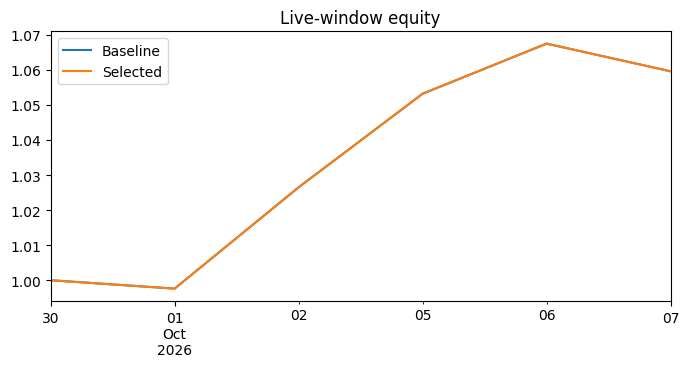

In [3]:
idx=C.index
prev=idx[idx<pd.Timestamp(LIVE_START)][-1]          # 实盘开始前最后一个收盘日
runs=run_all()
best,sc=select(runs,IS_START,str(prev.date()))
print(f'用 {prev.date()} 及以前的数据选参（冻结）:',label(best),'| 数据最后一天:',idx[-1].date())
res={};rows=[]
for n,c in [('基线（无止损止盈）',base),('选中参数',best)]:
    eq,tr=backtest(O,H,L,C,tg,c[1],c[2],c[0],5,10,start=str(prev.date()))
    e=eq.loc[str(prev.date()):LIVE_END]; res[n]=e
    rows.append({'方案':n,'区间':f'{e.index[1].date()}~{e.index[-1].date()}','交易日':len(e)-1,'累计收益':f'{e.iloc[-1]/e.iloc[0]-1:+.2%}','最大回撤':f'{(e/e.cummax()-1).min():.2%}'})
for t in ['SPY','TQQQ']:
    e=C[t].loc[str(prev.date()):LIVE_END]
    rows.append({'方案':'买入持有 '+t,'区间':f'{e.index[1].date()}~{e.index[-1].date()}','交易日':len(e)-1,'累计收益':f'{e.iloc[-1]/e.iloc[0]-1:+.2%}','最大回撤':f'{(e/e.cummax()-1).min():.2%}'})
display(pd.DataFrame(rows))
print('信号（每日收盘时的目标持仓）:'); display(tg.loc[str(prev.date()):LIVE_END].to_frame('target').T)
df=pd.DataFrame(res).round(4); display(df)
df.set_axis(['Baseline','Selected'],axis=1).plot(figsize=(8,3.5),title='Live-window equity'); plt.show()